In [1]:
import torch, torchvision
import numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
print(torch.__version__, torchvision.__version__)
print(torch.cuda.is_available())

2.14.1+cpu 0.29.2+cpu
False


In [3]:
arr = np.random.randn(2, 2)
arr

array([[-0.44059194,  0.39839679],
       [ 1.55197065,  0.31625826]])

In [4]:
arr.ndim

2

In [5]:
arr = np.random.randn(2, 2, 2)
arr

array([[[ 1.69475724,  0.77365838],
        [-0.23712122, -0.53834182]],

       [[ 0.20204054, -0.74491525],
        [-0.0473575 ,  0.52146879]]])

In [6]:
arr.ndim

3

In [7]:
arr = np.random.randn(2, 2, 2, 2)
arr

array([[[[ 0.06263689, -0.45615417],
         [-1.04236474,  1.56383472]],

        [[-1.26518063,  0.05852634],
         [ 1.05173505,  1.02907927]]],


       [[[-0.76239991,  1.48890514],
         [-0.82169962,  0.60159662]],

        [[-0.81589208, -0.84307922],
         [ 0.06357284,  0.57184706]]]])

In [8]:
arr.ndim

4

In [9]:
# Creating tensors from torch

scalar = torch.tensor(data=26, dtype=torch.int16)
scalar

tensor(26, dtype=torch.int16)

In [10]:
scalar.device, scalar.ndim

(device(type='cpu'), 0)

In [11]:
type(scalar.item())

int

In [12]:
type(scalar.data)

torch.Tensor

In [13]:
type(scalar)

torch.Tensor

In [14]:
matrix = torch.tensor(data=np.random.randn(2, 2))
matrix

tensor([[-0.7132,  0.2874],
        [-0.2141, -0.9689]], dtype=torch.float64)

In [15]:
matrix.ndim

2

In [16]:
matrix.shape, matrix.size()

(torch.Size([2, 2]), torch.Size([2, 2]))

In [17]:
tensor = torch.randn(size=(2, 2, 3))
tensor, tensor.ndim, tensor.shape

(tensor([[[ 1.3875, -1.0559, -0.1182],
          [-0.3680,  0.2894, -0.1582]],
 
         [[ 1.0771,  1.0928, -0.3754],
          [ 1.0230, -2.0135,  0.6333]]]),
 3,
 torch.Size([2, 2, 3]))

In [18]:
tensor.requires_grad

False

In [19]:
A = np.random.randn(3, 3)
A

array([[ 0.87323135, -0.92769341, -1.29596596],
       [ 1.24034117,  1.31424149, -0.23021815],
       [-0.55013573,  0.24243644, -0.9046226 ]])

In [20]:
tensor = torch.tensor(
    data=A, requires_grad=True
)
tensor

tensor([[ 0.8732, -0.9277, -1.2960],
        [ 1.2403,  1.3142, -0.2302],
        [-0.5501,  0.2424, -0.9046]], dtype=torch.float64, requires_grad=True)

In [21]:
x = torch.tensor(3, dtype=torch.float16, requires_grad=True)
print(x)
y = x**2


tensor(3., dtype=torch.float16, requires_grad=True)


In [22]:
import torch

# 1. Create a starting tensor (x = 3.0) and turn tracking on
x = torch.tensor(3.0, requires_grad=True)

# 2. Define the equation: y = x^2
y = x ** 2

# 3. Trigger the backpropagation engine
y.backward()

# 4. Check the calculated gradient
print(x.grad)


tensor(6.)


In [24]:
x.grad

tensor(6.)

In [25]:
tensor1 = torch.randn(size=(2, 2))
tensor2 = torch.randn(size=(2, 2))
tensor1, tensor2

(tensor([[-0.5080,  1.8242],
         [-0.2583,  0.7273]]),
 tensor([[-0.1479, -1.0491],
         [ 1.0822,  2.3872]]))

In [26]:
tensor1 * tensor2

tensor([[ 0.0752, -1.9138],
        [-0.2795,  1.7362]])

In [27]:
tensor1 @ tensor2

tensor([[2.0492, 4.8875],
        [0.8253, 2.0072]])

In [28]:
tensor1 - tensor2

tensor([[-0.3601,  2.8733],
        [-1.3405, -1.6598]])

In [29]:
torch.matmul(tensor1, tensor2)

tensor([[2.0492, 4.8875],
        [0.8253, 2.0072]])

In [30]:
vector = torch.tensor([1, 2.0])
vector

tensor([1., 2.])

In [31]:
torch.matmul(tensor1, vector)

tensor([3.1403, 1.1963])

In [32]:
torch.matmul(tensor1, vector.T)

C:\Users\hp\AppData\Local\Temp\ipykernel_2068\3573854501.py:1: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4323.)
  torch.matmul(tensor1, vector.T)


tensor([3.1403, 1.1963])

In [33]:
tensor1 @ vector

tensor([3.1403, 1.1963])

In [34]:
torch.linalg.eigvals(tensor1)

tensor([0.1096+0.2994j, 0.1096-0.2994j])

In [35]:
torch.inverse(tensor1)

tensor([[  7.1533, -17.9408],
        [  2.5404,  -4.9967]])

In [36]:
# torch.inverse(torch.tensor([
#     [1, 2],
#     [4, 8.0]
# ]))


arr =torch.tensor([
    [1, 2],
    [4, 8.0]
])

torch.linalg.matrix_rank(arr)



tensor(1)

In [37]:
t1 = torch.tensor(
    data=np.arange(1,5).reshape(2, 2),
    dtype=torch.float32
)
t2 = torch.tensor(
    data=np.arange(5,9).reshape(2, 2),
    dtype=torch.float32
)

t1, t2

(tensor([[1., 2.],
         [3., 4.]]),
 tensor([[5., 6.],
         [7., 8.]]))

In [38]:
t1 * t2

tensor([[ 5., 12.],
        [21., 32.]])

In [39]:
t1 + t2

tensor([[ 6.,  8.],
        [10., 12.]])

In [40]:
torch.matmul(t1, t2)

tensor([[19., 22.],
        [43., 50.]])

In [41]:
torch.linalg.svd(t1)

torch.return_types.linalg_svd(
U=tensor([[-0.4046, -0.9145],
        [-0.9145,  0.4046]]),
S=tensor([5.4650, 0.3660]),
Vh=tensor([[-0.5760, -0.8174],
        [ 0.8174, -0.5760]]))

In [42]:
torch.linalg.det(t1)

tensor(-2.)

In [43]:
torch.linalg.eig(t1)

torch.return_types.linalg_eig(
eigenvalues=tensor([-0.3723+0.j,  5.3723+0.j]),
eigenvectors=tensor([[-0.8246+0.j, -0.4160+0.j],
        [ 0.5658+0.j, -0.9094+0.j]]))

In [44]:
t1

tensor([[1., 2.],
        [3., 4.]])

In [45]:
t1.T

tensor([[1., 3.],
        [2., 4.]])

In [46]:
func = torch.nn.Linear(
    in_features=2, out_features=2,
    dtype=torch.float, device='cpu', 
)
func

Linear(in_features=2, out_features=2, bias=True)

In [47]:
func(t1)

tensor([[ 1.0419, -0.0936],
        [ 2.2691, -0.5310]], grad_fn=<AddmmBackward0>)

In [48]:
t1

tensor([[1., 2.],
        [3., 4.]])

In [49]:
func.bias

Parameter containing:
tensor([0.2164, 0.4830], requires_grad=True)

In [50]:
func.weight

Parameter containing:
tensor([[ 0.4016,  0.2120],
        [ 0.1393, -0.3579]], requires_grad=True)

In [51]:
torch.matmul(func.weight, t1[0]) + func.bias

tensor([ 1.0419, -0.0936], grad_fn=<AddBackward0>)

In [52]:
func.weight.T

tensor([[ 0.4016,  0.1393],
        [ 0.2120, -0.3579]], grad_fn=<PermuteBackward0>)

In [53]:
t1

tensor([[1., 2.],
        [3., 4.]])

In [54]:
t1[0] @ func.weight.T + func.bias

tensor([ 1.0419, -0.0936], grad_fn=<AddBackward0>)

In [55]:
t1.view(1, 4)

tensor([[1., 2., 3., 4.]])

In [56]:
t1

tensor([[1., 2.],
        [3., 4.]])

In [57]:
t1.reshape(1, 4)

tensor([[1., 2., 3., 4.]])

In [58]:
t1

tensor([[1., 2.],
        [3., 4.]])

In [59]:
t1 = t1.view(1, 4)
t1

tensor([[1., 2., 3., 4.]])

In [60]:
t1 = t1.reshape(2, 2)
torch.stack((t1, t1), dim = 2)

tensor([[[1., 1.],
         [2., 2.]],

        [[3., 3.],
         [4., 4.]]])

In [61]:
t1.squeeze().size()

torch.Size([2, 2])

In [62]:
arr = torch.arange(5).reshape(1, 5)
torch.concat((arr, arr, arr), dim=0)

tensor([[0, 1, 2, 3, 4],
        [0, 1, 2, 3, 4],
        [0, 1, 2, 3, 4]])

In [63]:
arr.shape, arr.squeeze().shape

(torch.Size([1, 5]), torch.Size([5]))

In [64]:
arr.squeeze().unsqueeze(dim=1)

tensor([[0],
        [1],
        [2],
        [3],
        [4]])

In [65]:
arr = torch.randn(size=(2, 2, 3))
arr, arr.size()

(tensor([[[-0.1627, -0.3346,  0.3520],
          [-1.3508,  1.4244, -0.9706]],
 
         [[ 1.7586,  0.2581, -0.1650],
          [-1.4593, -0.2282, -0.9388]]]),
 torch.Size([2, 2, 3]))

In [66]:
print(arr.permute(dims=(2, 1, 0)))#swaps the dimension of the columns with the layer
arr.permute(dims=(2, 1, 0)).size()

tensor([[[-0.1627,  1.7586],
         [-1.3508, -1.4593]],

        [[-0.3346,  0.2581],
         [ 1.4244, -0.2282]],

        [[ 0.3520, -0.1650],
         [-0.9706, -0.9388]]])


torch.Size([3, 2, 2])

In [67]:
x = torch.arange(1, 10).reshape(1, 3, 3)
x

tensor([[[1, 2, 3],
         [4, 5, 6],
         [7, 8, 9]]])

In [68]:
x[0]

tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])

In [69]:
x[:, :]

tensor([[[1, 2, 3],
         [4, 5, 6],
         [7, 8, 9]]])

In [70]:
x[:, :, :]

tensor([[[1, 2, 3],
         [4, 5, 6],
         [7, 8, 9]]])

In [71]:
x[:, 2, :2]

tensor([[7, 8]])

In [72]:
x[0, 0, :]

tensor([1, 2, 3])

In [73]:
w, b = 0.5, 1
X = torch.arange(0, 20, 0.3).unsqueeze(1)
y = w * X + b
train_size = int(0.8 * len(X))

X_train, X_test = X[: train_size], X[train_size: ]
y_train, y_test = y[: train_size], y[train_size: ]


def plot_prediction(
    train_data, train_labels, 
    test_data, test_labels, 
    prediction=None
):
    plt.figure()
    plt.scatter(train_data, train_labels, color='blue', label='Training Data')
    plt.scatter(test_data, test_labels, color='red', label='Test Data')
    if prediction is not None:
        plt.scatter(test_data, prediction, color='black', label='Prediction')
    plt.legend()
    plt.show()
    

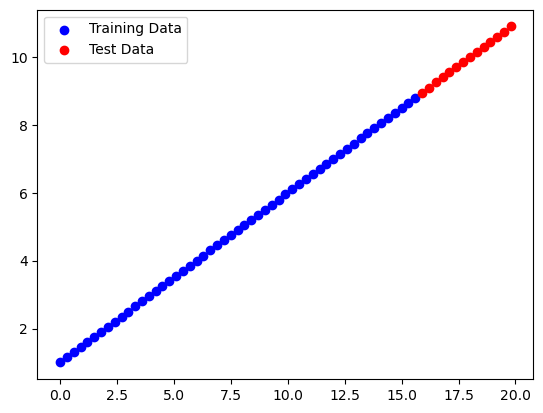

In [74]:
plot_prediction(X_train, y_train, X_test, y_test)

In [75]:
class My_Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.randn(1))
        self.b = nn.Parameter(torch.randn(1))

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.w * X + self.b

whatever backward is above, and grad is below in the following example

it is dy/dx

In [76]:
x = torch.tensor(5.0, requires_grad=True)
y = 2*(x**2)
y.backward()
x.grad


tensor(20.)

In [77]:
x = torch.tensor([2.0, 3], requires_grad=True)
y = x**2
y.sum().backward()
x.grad

tensor([4., 6.])

In [78]:
x = torch.tensor(2.0, requires_grad=True)
y = x**2
z = y**2


y.retain_grad()
z.backward()
y.grad, x.grad

(tensor(8.), tensor(32.))

Here it is dz/dy = 2y, which is 2(x^2) which is 8


to get dz/dx, here the analogy is that z is the inner most function and x is outermost to get the derivative to z wrt x we have to do chain rule

dz/dy* (dy/dx) = 8(4) = 32

In [79]:
lin_reg = My_Model()

list(lin_reg.parameters())

[Parameter containing:
 tensor([0.3336], requires_grad=True),
 Parameter containing:
 tensor([0.4877], requires_grad=True)]

In [80]:
with torch.inference_mode():
    pred = lin_reg(X_test)
pred[0], X_test[0], y_test[0]

(tensor([5.7918]), tensor([15.9000]), tensor([8.9500]))

In [81]:
lin_reg.w * X_test[0] + lin_reg.b

tensor([5.7918], grad_fn=<AddBackward0>)

so torch.inference_model only predicts with the parameters, it uses the forward path defined inside the class

In [82]:
lin_reg(X_test)[0] #__callable__ method changed by the pytorch nn.MOdule

tensor([5.7918], grad_fn=<SelectBackward0>)

In [83]:
lin_reg.forward(X_test)[0]

tensor([5.7918], grad_fn=<SelectBackward0>)

with inference_mode and lin_reg(X_test) forward pass does not track the gradients

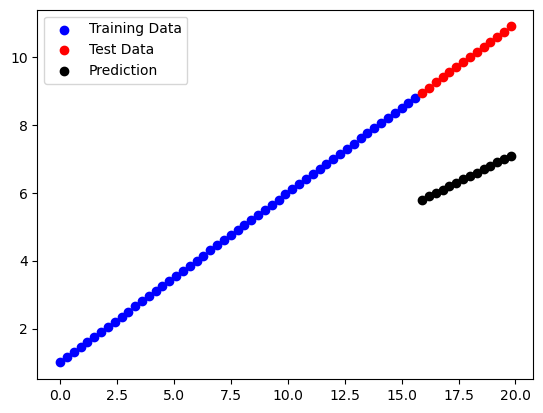

In [84]:
plot_prediction(
    X_train, y_train, 
    X_test, y_test, 
    pred
)

In [85]:
loss = nn.MSELoss()
optimizer = torch.optim.SGD(params=lin_reg.parameters(), lr=1e-4)

In [86]:
# Initialzing again for retraining
lin_reg = My_Model()
loss = nn.MSELoss()
optimizer = torch.optim.SGD(params=lin_reg.parameters(), lr=1e-2)

In [87]:
# Training the model 

epochs = 600
training_loss, test_loss = [], []
for epoch in range(epochs):
    lin_reg.train()    #This just sets the model in the training mode
    y_pred = lin_reg(X_train)    #Forward Pass using the __call__ method, tracks the gradient because the parameters we set has require_grad=True
    error = loss(y_pred, y_train) #Computes the loss after each pass

    optimizer.zero_grad()    #This resets the gradient at every epoch, so it does not mix with the previous gradients of previous epochs
    error.backward()    #Backward pass from the loss function 
    optimizer.step()    #Makes the gradient descent
    training_loss.append(error.detach().numpy())

    lin_reg.eval()     #In testing mode
    with torch.inference_mode():
        test_error = loss(lin_reg(X_test), y_test)
        test_loss.append(test_error)


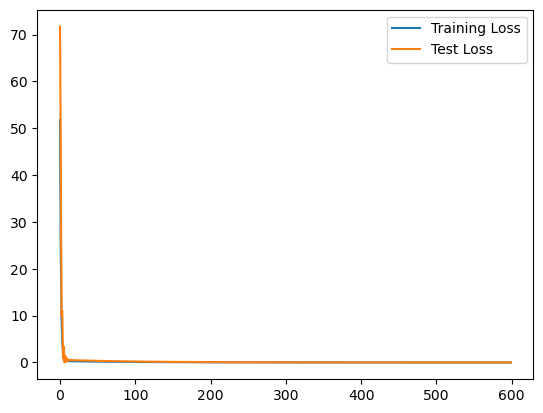

In [88]:
plt.plot(training_loss, label='Training Loss')
plt.plot(test_loss, label='Test Loss')
plt.legend()
plt.show()

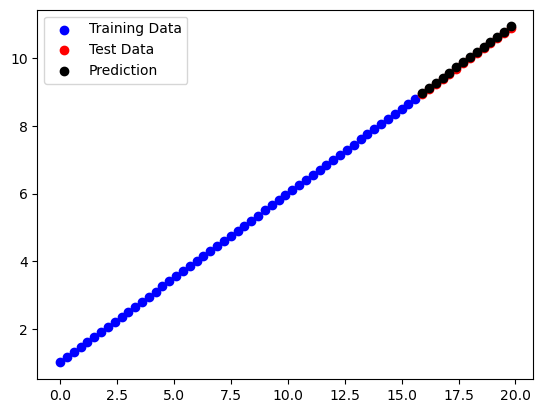

In [89]:
with torch.inference_mode():
    y_pred = lin_reg(X_test)

plot_prediction(
    X_train, y_train, X_test, y_test, 
    prediction=y_pred
)

In [90]:
lin_reg.w, w

(Parameter containing:
 tensor([0.5048], requires_grad=True),
 0.5)

In [91]:
lin_reg.b, b

(Parameter containing:
 tensor([0.9501], requires_grad=True),
 1)

In [92]:

dict(lin_reg.state_dict())

{'w': tensor([0.5048]), 'b': tensor([0.9501])}

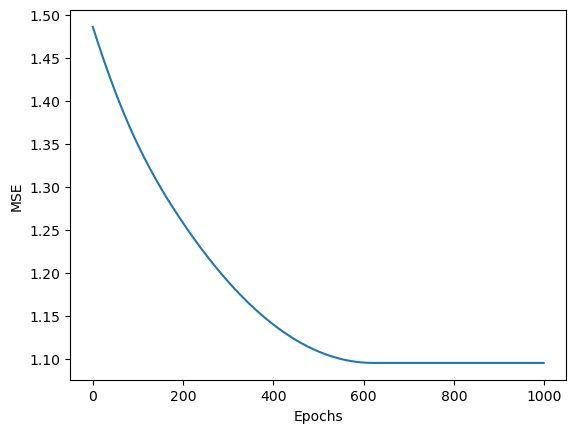

In [93]:
class LinearReg(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = torch.nn.Linear(2, 1)

    def forward(self, X: torch.Tensor):
        return self.linear_layer(X)

X = torch.randn(size=(100, 2))
y = torch.randn(size=(100, )).unsqueeze(1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
model = LinearReg()
optimizer = torch.optim.Adam(
    betas=(0.9, 0.9), 
    params=model.parameters(),
    lr=1e-3
)
loss_fn = nn.MSELoss()
history = []
for i in range(1000):
    model.train()
    loss = loss_fn(model(X), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    history.append(loss.detach().numpy())

plt.figure()
plt.plot(history)
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.show()
    

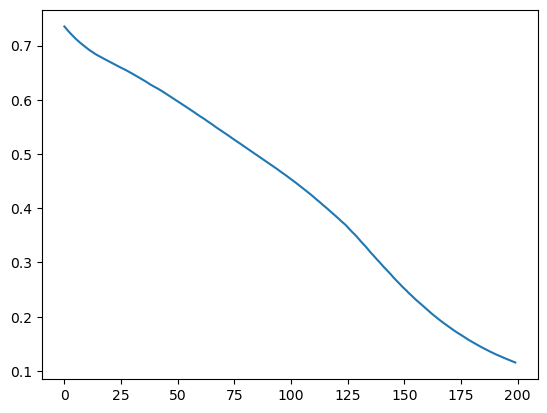

In [94]:
#Creating MLP for xor gate 

X = torch.tensor([[0, 0],
                  [0, 1],
                  [1, 0],
                  [1, 1]], dtype=torch.float32)
y = torch.tensor([0, 1, 1, 0], dtype=torch.float32).unsqueeze(1)
loss_fn = nn.BCELoss()

class Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden_layer = nn.Linear(2, 8)
        self.hidden_activation = nn.ReLU()
        self.output_neuron = nn.Linear(8, 1)
        self.output_activation = nn.Sigmoid()

    def forward(self, X):
        h1 = self.hidden_activation(self.hidden_layer(X))
        y = self.output_activation(self.output_neuron(h1))
        return y

mlp = Model()
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-2)
epochs = 200
training_loss = []
validation_loss = []
for i in range(epochs):
    mlp.train()
    loss = loss_fn(mlp(X), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    training_loss.append(loss.detach().numpy())

plt.figure()
plt.plot(training_loss)
plt.plot(validation_loss)
plt.show()

In [95]:
with torch.inference_mode():
    y_pred = (mlp(X) > 0.5).int()
    h = torch.relu(mlp.hidden_layer(X))
h, y_pred

(tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [2.0765, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 1.9167, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.6919, 0.0000, 0.0000, 0.0035, 0.0000, 0.0000, 0.0000, 1.5454]]),
 tensor([[0],
         [1],
         [1],
         [0]], dtype=torch.int32))

In [96]:
mlp.state_dict()

OrderedDict([('hidden_layer.weight',
              tensor([[-1.3845,  2.0798],
                      [ 0.2040, -0.1960],
                      [-0.3290, -0.0301],
                      [ 1.9184, -1.9132],
                      [-0.5398,  0.5052],
                      [ 0.2916, -0.5543],
                      [-0.6632,  0.3026],
                      [ 1.5477,  1.5461]])),
             ('hidden_layer.bias',
              tensor([-0.0033, -0.3341, -0.2641, -0.0017, -0.6753, -0.3607, -0.4726, -1.5484])),
             ('output_neuron.weight',
              tensor([[ 1.8081,  0.2879,  0.1493,  2.0212, -0.1429, -0.1024, -0.0804, -1.8962]])),
             ('output_neuron.bias', tensor([-1.2234]))])

In [97]:
from sklearn.datasets import load_iris 
from sklearn.preprocessing import StandardScaler
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.from_numpy(X_train).float()
X_test = torch.from_numpy(X_test).float()
y_train = torch.from_numpy(y_train).long()
y_test = torch.from_numpy(y_test).long()


X.shape, y.shape

((150, 4), (150,))

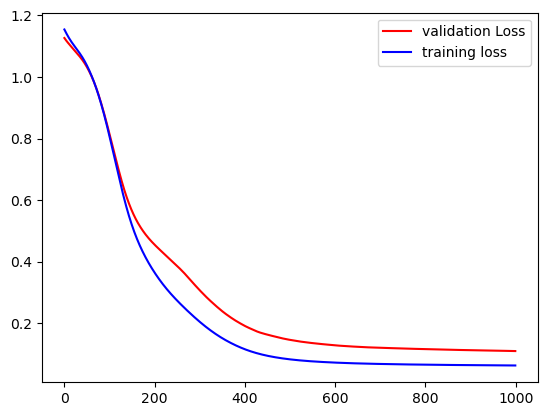

In [98]:
class Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(X.shape[-1], 16)
        self.layer_1_activation = nn.ReLU()
        self.layer_2 = nn.Linear(16, 8)
        self.layer_2_activation = nn.ReLU()
        self.layer_3 = nn.Linear(8, 3)
        self.layer_3_activation = nn.Softmax()   #softmax is applied uisng cross entropy loss

    def forward(self, X):
        return self.layer_3(self.layer_2_activation(self.layer_2(self.layer_1_activation(self.layer_1(X)))))
    

loss_fn = nn.CrossEntropyLoss()
model = Model()
optimizer = torch.optim.Adam(lr=0.001, params=model.parameters(), weight_decay=1e-2)


epochs = 1000
train_loss, validation_loss = [], []

for i in range(epochs):
    model.train()
    loss = loss_fn(model(X_train), y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_loss.append(loss.detach().numpy())

    model.eval()
    with torch.inference_mode():
        val_loss = loss_fn(model(X_test), y_test)
    validation_loss.append(val_loss.item())

    
plt.figure()
plt.plot(validation_loss, label='validation Loss', color='red')
plt.plot(train_loss, label='training loss', color='blue')
plt.legend()
plt.show()

In [100]:
from sklearn.metrics import confusion_matrix
with torch.inference_mode():
    logits = model(X_test)
    pred = logits.argmax(dim=1)                 
    probs = torch.softmax(logits, dim=1)        

confusion_matrix(y_test, pred)

array([[7, 0, 0],
       [0, 7, 1],
       [0, 0, 8]])